In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os, shutil
import random
import tensorflow as tf
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
import shutil

In [2]:
from google.colab import drive

# Drive'a erişim izni
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip /content/drive/MyDrive/png.zip

Görüntülenen çıkış son 5000 satıra kısaltıldı.
  inflating: all/abnormal/S(83-167)0058.png  
  inflating: all/abnormal/S(83-167)0059.png  
  inflating: all/abnormal/S(83-167)0060.png  
  inflating: all/abnormal/S(83-167)0061.png  
  inflating: all/abnormal/S(83-167)0062.png  
  inflating: all/abnormal/S(83-167)0063.png  
  inflating: all/abnormal/S(83-167)0064.png  
  inflating: all/abnormal/S(83-167)0065.png  
  inflating: all/abnormal/S(83-167)0066.png  
  inflating: all/abnormal/S(83-167)0067.png  
  inflating: all/abnormal/S(83-167)0068.png  
  inflating: all/abnormal/S(83-167)0069.png  
  inflating: all/abnormal/S(83-167)0070.png  
  inflating: all/abnormal/S(83-167)0071.png  
  inflating: all/abnormal/S(83-167)0072.png  
  inflating: all/abnormal/S(83-167)0073.png  
  inflating: all/abnormal/S(83-167)0074.png  
  inflating: all/abnormal/S(83-167)0075.png  
  inflating: all/abnormal/S(83-167)0076.png  
  inflating: all/abnormal/S(83-167)0077.png  
  inflating: all/abnormal/S(83-16

In [4]:
import os
import shutil
from sklearn.model_selection import train_test_split



data_directory = '/content/all'

os.makedirs("/content/all_data")

train_directory = '/content/all_data/train'
test_directory = '/content/all_data/test'


normal_images = os.listdir(os.path.join(data_directory, 'normal'))
abnormal_images = os.listdir(os.path.join(data_directory, 'abnormal'))

normal_train, normal_test = train_test_split(normal_images, test_size=0.2, random_state=42)
abnormal_train, abnormal_test = train_test_split(abnormal_images, test_size=0.2, random_state=42)

os.makedirs(os.path.join(train_directory, 'normal'), exist_ok=True)
os.makedirs(os.path.join(train_directory, 'abnormal'), exist_ok=True)
os.makedirs(os.path.join(test_directory, 'normal'), exist_ok=True)
os.makedirs(os.path.join(test_directory, 'abnormal'), exist_ok=True)

for image in normal_train:
    shutil.copy(os.path.join(data_directory, 'normal', image), os.path.join(train_directory, 'normal', image))
for image in abnormal_train:
    shutil.copy(os.path.join(data_directory, 'abnormal', image), os.path.join(train_directory, 'abnormal', image))


for image in normal_test:
    shutil.copy(os.path.join(data_directory, 'normal', image), os.path.join(test_directory, 'normal', image))
for image in abnormal_test:
    shutil.copy(os.path.join(data_directory, 'abnormal', image), os.path.join(test_directory, 'abnormal', image))


In [5]:
print('test normal : ' , len(os.listdir('/content/all_data/test/normal')))
print('test abnormal : ' , len(os.listdir('/content/all_data/test/abnormal')))
print('train normal : ' , len(os.listdir('/content/all_data/train/normal')))
print('train abnormal : ' , len(os.listdir('/content/all_data/train/abnormal')))

test normal :  617
test abnormal :  597
train normal :  2467
train abnormal :  2386


In [25]:
import glob
import cv2

# test
test_images = []
test_labels = []

for path in glob.glob("/content/all_data/test/*"):
  label = path.split("/")[-1]
  print(label)

  for image_path in glob.glob(os.path.join(path , "*.png")):
    #print(image_path)
    img = cv2.imread(image_path , cv2.IMREAD_COLOR)
    img = cv2.resize(img , (224,224))
    img = cv2.cvtColor(img , cv2.COLOR_RGB2BGR)
    test_images.append(img)
    test_labels.append(label)




abnormal
normal


In [26]:
test_labels = np.array(test_labels)



In [33]:
# encoding labels
from sklearn import preprocessing
le = preprocessing.LabelEncoder()
le.fit(test_labels)
y_test = le.transform(test_labels)



In [6]:
from keras.preprocessing.image import ImageDataGenerator
train_dir = "/content/all_data/train"
test_dir = "/content/all_data/test"


train_datagen = ImageDataGenerator(rescale=1/255.)
test_datagen = ImageDataGenerator(rescale=1/255.)


train = train_datagen.flow_from_directory(train_dir ,
                                          target_size = (512,512),
                                          batch_size=64,
                                          class_mode="binary")

test = test_datagen.flow_from_directory(test_dir ,
                                          target_size = (512,512),
                                          batch_size=64,
                                          class_mode="binary")



Found 4853 images belonging to 2 classes.
Found 1214 images belonging to 2 classes.


In [7]:
train_data , train_label = train.next()

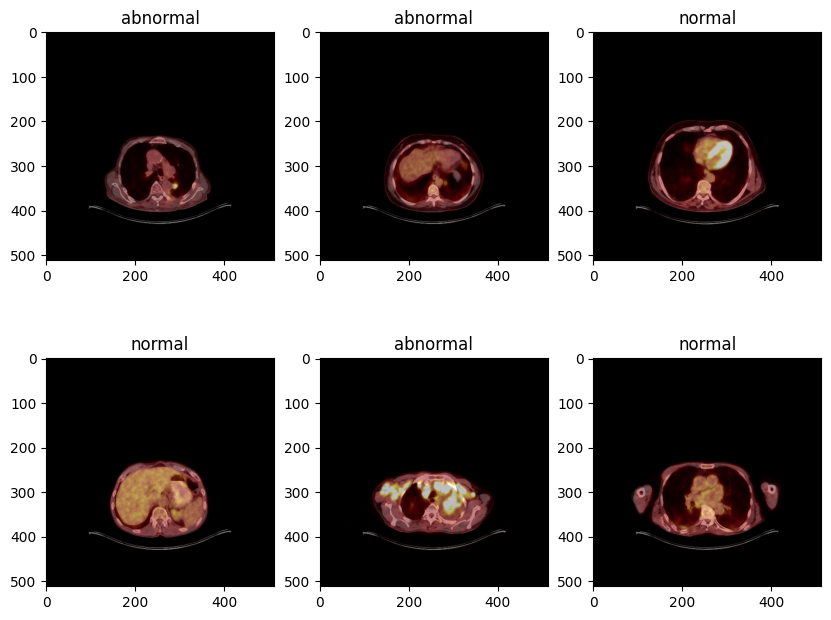

In [8]:
class_name = ['abnormal','normal']
plt.figure(figsize = (10,12))

for i in range(6):
  ax = plt.subplot(3,3, i+1)
  random_index = random.choice(range(len(train_data)))

  plt.imshow(train_data[random_index] , cmap = plt.cm.binary)
  plt.title(class_name[int(train_label[random_index])])
  plt.axis=False

# vgg 16  transfer learning

In [9]:
from keras.applications import VGG16

base_line = VGG16(weights="imagenet",
                  include_top = False,
                  input_shape =  (512,512,3))

58889256/58889256 [==============================] - 0s 0us/step


In [10]:
base_line.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 512, 512, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 512, 512, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 512, 512, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 256, 256, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 256, 256, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 256, 256, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 128, 128, 128)     0     

In [11]:
base_line.trainable = False

In [12]:
base_line.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 512, 512, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 512, 512, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 512, 512, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 256, 256, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 256, 256, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 256, 256, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 128, 128, 128)     0     

In [13]:
from keras import models
from keras import layers

model1 = models.Sequential()
model1.add(base_line)
model1.add(layers.Flatten())
model1.add(layers.Dense(512 , activation="relu"))
model1.add(layers.Dense(1 , activation="sigmoid"))

In [14]:
from keras.optimizers import RMSprop
model1.compile(loss='binary_crossentropy',
              optimizer=RMSprop(learning_rate=1e-4),
              metrics=['accuracy'])

In [15]:
from keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='accuracy', patience=5, verbose=1)

history1 = model1.fit(train,
                              steps_per_epoch=len(train),
                              epochs=15,
                              validation_data=test,
                              validation_steps=len(test),
                              callbacks=[early_stopping])


Epoch 1/15
76/76 [==============================] - 263s 3s/step - loss: 1.2561 - accuracy: 0.5213 - val_loss: 0.6886 - val_accuracy: 0.5601
Epoch 2/15
76/76 [==============================] - 143s 2s/step - loss: 0.6684 - accuracy: 0.6225 - val_loss: 0.8277 - val_accuracy: 0.5362
Epoch 3/15
76/76 [==============================] - 128s 2s/step - loss: 0.6092 - accuracy: 0.6627 - val_loss: 0.5677 - val_accuracy: 0.6952
Epoch 4/15
76/76 [==============================] - 128s 2s/step - loss: 0.5311 - accuracy: 0.7344 - val_loss: 0.6593 - val_accuracy: 0.6145
Epoch 5/15
76/76 [==============================] - 144s 2s/step - loss: 0.4943 - accuracy: 0.7587 - val_loss: 0.4412 - val_accuracy: 0.7867
Epoch 6/15
76/76 [==============================] - 128s 2s/step - loss: 0.4521 - accuracy: 0.7731 - val_loss: 0.4038 - val_accuracy: 0.8138
Epoch 7/15
76/76 [==============================] - 128s 2s/step - loss: 0.4313 - accuracy: 0.8012 - val_loss: 0.5631 - val_accuracy: 0.7100
Epoch 8/15
76

In [16]:
model1.evaluate(test)

19/19 [==============================] - 27s 1s/step - loss: 0.2666 - accuracy: 0.8970


[0.2666405737400055, 0.8970345854759216]

In [17]:
model1.save('model1_512_dense.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [18]:
def loss(history):

  loss = history.history["loss"]
  val_loss= history.history["val_loss"]

  accuracy = history.history["accuracy"]
  val_accuracy = history.history["val_accuracy"]


  epochs = range(len(history.history["loss"]))

  plt.plot(epochs , loss , label="training loss")
  plt.plot(epochs , val_loss , label="training val_loss")
  plt.xlabel(epochs)
  plt.title("loss")
  plt.legend()


  plt.figure()
  plt.plot(epochs , accuracy , label="training accuracy")
  plt.plot(epochs , val_accuracy , label="training val_accuracy")
  plt.title("accuracy")
  plt.xlabel(epochs)
  plt.legend()

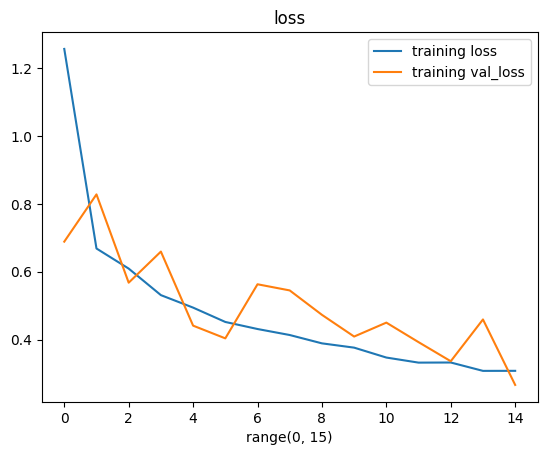

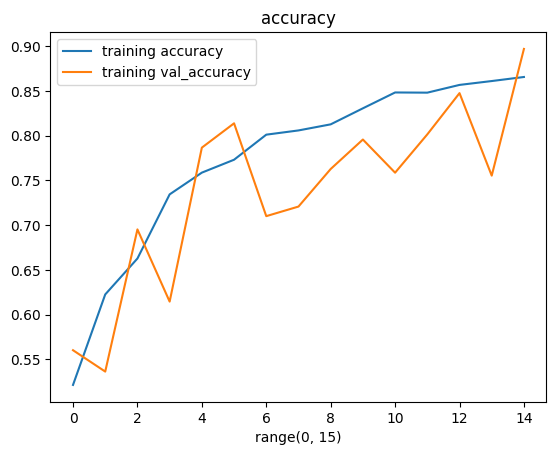

In [19]:
loss(history1)

In [46]:
# Modeli değerlendirme
evaluation = model1.evaluate(test)

# Doğruluk ve kayıp değerleri
accuracy = evaluation[1]
loss = evaluation[0]

print(f"Test seti üzerinde doğruluk: {accuracy}")
print(f"Test seti üzerinde kayıp: {loss}")


19/19 [==============================] - 26s 1s/step - loss: 0.2666 - accuracy: 0.8970
Test seti üzerinde doğruluk: 0.8970345854759216
Test seti üzerinde kayıp: 0.2666405141353607


In [47]:
from sklearn import metrics
print ("Accuracy = ", metrics.accuracy_score(true_labels, predicted_labels))

Accuracy =  0.4802306425041186


19/19 [==============================] - 24s 1s/step


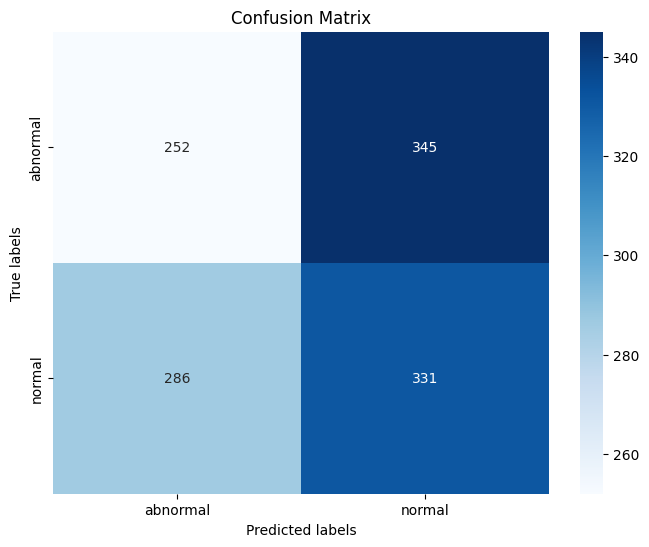

In [45]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

#class_name = os.listdir('/content/all_data/test')
# Test seti üzerinde tahminler yap
predictions = model1.predict(test)
predicted_labels = np.where(predictions > 0.5, 1, 0)  # Eşik değerine göre tahminleri etiketlere dönüştür

true_labels = test.labels  # Gerçek etiketler

# Confusion matrix oluştur
cm = confusion_matrix(true_labels, predicted_labels)

# Görselleştirme
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_name, yticklabels=class_name)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()
